In [ ]:
import pandas as pd
import numpy as np





In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Student_Performance.csv to Student_Performance (1).csv


In [ ]:
df1 = pd.read_csv("../../data/Student_Performance.csv")

In [ ]:
df1

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
...,...,...,...,...,...,...
9995,1,49,Yes,4,2,23.0
9996,7,64,Yes,8,5,58.0
9997,6,83,Yes,8,5,74.0
9998,9,97,Yes,7,0,95.0


In [ ]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [ ]:
df1 = pd.get_dummies(df1, columns= ['Extracurricular Activities'], dtype=int)

In [ ]:
df1

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index,Extracurricular Activities_No,Extracurricular Activities_Yes
0,7,99,9,1,91.0,0,1
1,4,82,4,2,65.0,1,0
2,8,51,7,2,45.0,0,1
3,5,52,5,2,36.0,0,1
4,7,75,8,5,66.0,1,0
...,...,...,...,...,...,...,...
9995,1,49,4,2,23.0,0,1
9996,7,64,8,5,58.0,0,1
9997,6,83,8,5,74.0,0,1
9998,9,97,7,0,95.0,0,1


In [ ]:
X = df1.drop('Performance Index', axis=1)
y = df1['Performance Index']

In [ ]:
X

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Extracurricular Activities_No,Extracurricular Activities_Yes
0,7,99,9,1,0,1
1,4,82,4,2,1,0
2,8,51,7,2,0,1
3,5,52,5,2,0,1
4,7,75,8,5,1,0
...,...,...,...,...,...,...
9995,1,49,4,2,0,1
9996,7,64,8,5,0,1
9997,6,83,8,5,0,1
9998,9,97,7,0,0,1


In [ ]:
y

,Performance Index
0,91.0
1,65.0
2,45.0
3,36.0
4,66.0
...,...
9995,23.0
9996,58.0
9997,74.0
9998,95.0


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [ ]:
len(X_test)

2000

In [ ]:
from sklearn.linear_model import LinearRegression

regressor = LinearRegression()
regressor.fit(X_train, y_train)



LinearRegression()

In [ ]:
y_pred = regressor.predict(X_test)

In [ ]:
y_pred

array([54.71185392, 22.61551294, 47.90314471, ..., 16.79341955,
       63.34327368, 45.94262301])

In [ ]:
y_test

,Performance Index
6252,51.0
4684,20.0
1731,46.0
4742,28.0
4521,41.0
...,...
6412,45.0
8285,66.0
7853,16.0
1095,65.0


In [ ]:
import matplotlib.pyplot as plt

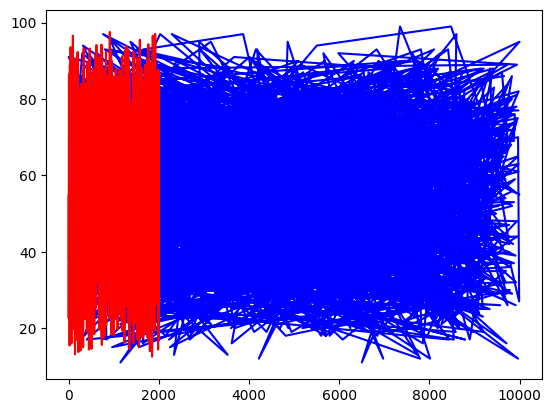

In [ ]:
plt.plot(y_test, color = 'blue', label = 'test')
plt.plot(y_pred, color = 'red', label = 'predictions')

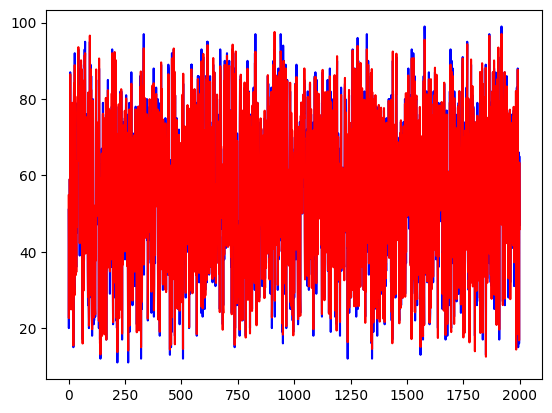

In [ ]:
y_test = y_test.to_numpy()
plt.plot(y_test, color = 'blue', label = 'test')
plt.plot(y_pred, color = 'red', label = 'predictions')

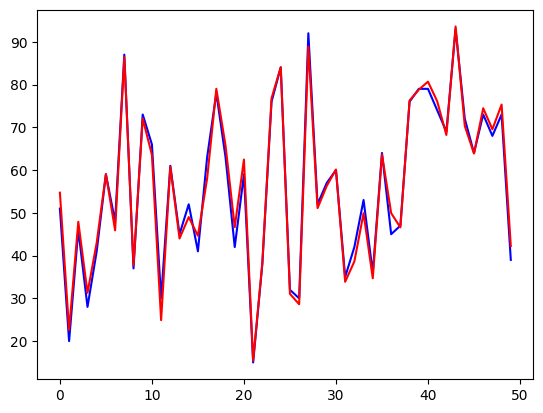

In [ ]:
plt.plot(y_test[:50], color = 'blue', label = 'test')
plt.plot(y_pred[:50], color = 'red', label = 'predictions')

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
mae=mean_absolute_error(y_test, y_pred)
mae

1.6111213463123037

In [ ]:
mse = mean_squared_error(y_test, y_pred)
mse

4.082628398521852

In [ ]:
r2 = r2_score(y_test, y_pred)
r2

0.9889832909573145

In [ ]:
regressor.coef_

array([ 2.85248393,  1.0169882 ,  0.47694148,  0.19183144, -0.30430834,
        0.30430834])

In [ ]:
regressor.intercept_

np.float64(-33.61763787576816)